# Natural Language Processing — Lab 2: Word Embeddings (Word2Vec & GloVe)

This laboratory explores the shift from sparse lexical representations to dense, continuous vector spaces
where geometric proximity encodes semantic meaning. We study and implement the two foundational pillars
of distributed representations:

1. **Word2Vec** (Mikolov et al., 2013) — Predictive neural architectures: **Continuous Bag-of-Words (CBOW)** and **Skip-Gram with Negative Sampling (SGNS)** using `gensim`.
2. **GloVe** (Pennington et al., 2014) — Global co-occurrence matrix factorization and weighted least-squares regression implemented from first principles.
3. **Count-based SVD Baseline** — Positive Pointwise Mutual Information (PPMI) factorized via `scikit-learn` TruncatedSVD.
4. **Comparative Analysis & Visualization** — Evaluating cosine similarity metrics (`scikit-learn`) and visualizing 2D semantic clusters and linear analogies (`PCA` + `matplotlib`).

**Libraries**: `nltk`, `gensim`, `scikit-learn`, `numpy`, `pandas`, `matplotlib`.

In [1]:
# ====================================================================
# Environment Setup & Imports
# ====================================================================
import math
import random
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# NLP & ML Libraries
import nltk
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

# Set random seeds for exact reproducibility
random.seed(42)
np.random.seed(42)

# Download essential NLTK assets
for res in ["punkt", "punkt_tab", "stopwords"]:
    try:
        nltk.download(res, quiet=True)
    except Exception as e:
        print(f"NLTK download notice ({res}): {e}")

print("Environment initialized: all libraries and modules loaded successfully.")

Environment initialized: all libraries and modules loaded successfully.


---
## 1. Corpus Preprocessing & Vocabulary Structuring (`nltk`)

Distributed representations learn from the contexts in which words appear (Firth's Distributional Hypothesis:
*"You shall know a word by the company it keeps"*).

To demonstrate semantic clustering and vector analogies (such as $\vec{v}_{\text{king}} - \vec{v}_{\text{man}} + \vec{v}_{\text{woman}} \approx \vec{v}_{\text{queen}}$),
we construct a domain-structured corpus with clearly defined semantic fields:
- **Royalty**: *king, queen, prince, princess, rule, kingdom, crown, palace, throne*
- **Gender & People**: *man, woman, boy, girl, king, queen, father, mother*
- **Fruits & Food**: *apple, banana, orange, fruit, eat, sweet, delicious*

We use `nltk.tokenize.word_tokenize` to reliably tokenize text and normalize terms to lowercase.

In [2]:
# Raw sentences designed with explicit semantic and analogical relations
raw_corpus = [
    # Royalty domain
    "the powerful king rules the kingdom with wisdom",
    "the gracious queen rules the kingdom beside the king",
    "the prince is the young royal son of the king and queen",
    "the princess is the royal daughter of the king and queen",
    "the king wears a golden crown and sits on the throne in the palace",
    "the queen wears a shining crown and sits on the throne in the palace",
    "the king and queen love the kingdom and protect the people",
    "the prince and princess live in the grand palace",
    "the royal throne and the golden crown belong to the king and queen",
    
    # People & Gender parallels
    "a man and a woman work hard in the village",
    "the man is strong and the woman is wise",
    "the boy is the young son of the man and woman",
    "the girl is the young daughter of the man and woman",
    "a man loves a woman and they care for the boy and girl",
    "every man and woman in the kingdom respects the king and queen",
    
    # Fruits & Food domain
    "apple and banana and orange are fresh sweet fruits",
    "the man eats a sweet apple and a delicious banana",
    "the woman eats a fresh orange and a sweet apple every day",
    "the boy eats a banana and the girl eats an apple",
    "fruits like apple banana and orange are delicious and healthy",
    "eating a fresh apple and sweet fruit gives energy to the boy and girl",
    "the children love to eat fresh fruit in the garden",
]

def preprocess_sentence(sentence):
    tokens = word_tokenize(sentence.lower())
    # Filter out lone punctuation symbols while keeping alphanumeric tokens
    return [t for t in tokens if t.isalnum()]

# Repeat corpus to provide sufficient gradient signal for our lightweight embedding models
tokenized_corpus = [preprocess_sentence(s) for s in raw_corpus] * 40

# Compute vocabulary statistics
flat_tokens = [w for sent in tokenized_corpus for w in sent]
vocab_counts = Counter(flat_tokens)

print(f"Total training sentences : {len(tokenized_corpus)}")
print(f"Total training tokens    : {len(flat_tokens)}")
print(f"Unique vocabulary size   : {len(vocab_counts)}")
print("\nMost frequent words:", vocab_counts.most_common(8))

Total training sentences : 880
Total training tokens    : 9720
Unique vocabulary size   : 71

Most frequent words: [('the', 1760), ('and', 1040), ('a', 480), ('king', 320), ('queen', 280), ('man', 280), ('woman', 280), ('is', 240)]


---
## 2. Word2Vec Deep Dive (`gensim`): CBOW vs Skip-Gram

Word2Vec learns continuous representations by setting up a self-supervised prediction task over sliding context windows:

- **Continuous Bag-of-Words (CBOW)**:
  $$\bar{v} = \frac{1}{2c} \sum_{-c \le j \le c, j \neq 0} v_{w_{t+j}}, \quad P(w_t \mid \text{context}) = \frac{\exp({v'_{w_t}}^\top \bar{v})}{\sum_{w \in V} \exp({v'_w}^\top \bar{v})}$$
  Averages context vectors to predict the center word. Fast, smooths across frequent context words.

- **Skip-Gram with Negative Sampling (SGNS)**:
  $$\mathcal{L}_{\text{SGNS}} = \log \sigma({v'_{w_c}}^\top v_{w_t}) + \sum_{i=1}^k \mathbb{E}_{w_i \sim P_n(w)} \left[ \log \sigma(-{v'_{w_i}}^\top v_{w_t}) \right]$$
  Predicts each context word from the center word. Better suited for rare words and fine-grained analogical relations.

We train both architectures using `gensim.models.Word2Vec`.

In [3]:
# --------------------------------------------------------------------
# 1. Train Word2Vec Skip-Gram (sg=1)
# --------------------------------------------------------------------
w2v_skipgram = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=50,       # 50-dimensional dense vectors
    window=3,             # context window: 3 words left, 3 words right
    min_count=1,          # include all vocabulary tokens
    sg=1,                 # 1 = Skip-Gram
    negative=5,           # 5 negative samples per positive pair
    sample=1e-3,          # subsampling threshold for frequent words
    epochs=120,           # training iterations
    seed=42,
    workers=1
)

# --------------------------------------------------------------------
# 2. Train Word2Vec CBOW (sg=0)
# --------------------------------------------------------------------
w2v_cbow = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=50,
    window=3,
    min_count=1,
    sg=0,                 # 0 = CBOW
    negative=5,
    sample=1e-3,
    epochs=120,
    seed=42,
    workers=1
)

print("Word2Vec Skip-Gram and CBOW models successfully trained.")

Word2Vec Skip-Gram and CBOW models successfully trained.


In [4]:
# Inspect nearest neighbors for 'king' and 'apple'
print("=== Most Similar to 'king' ===")
print("Skip-Gram :", [w for w, s in w2v_skipgram.wv.most_similar("king", topn=4)])
print("CBOW      :", [w for w, s in w2v_cbow.wv.most_similar("king", topn=4)])

print("\n=== Most Similar to 'apple' ===")
print("Skip-Gram :", [w for w, s in w2v_skipgram.wv.most_similar("apple", topn=4)])
print("CBOW      :", [w for w, s in w2v_cbow.wv.most_similar("apple", topn=4)])

# Semantic similarity comparisons
print("\n=== Cosine Similarity Comparison (Skip-Gram) ===")
sim_royal = w2v_skipgram.wv.similarity("king", "queen")
sim_cross = w2v_skipgram.wv.similarity("king", "apple")
sim_fruits = w2v_skipgram.wv.similarity("apple", "banana")

print(f"cos(king, queen)   = {sim_royal:.4f}  (Same semantic domain: Royalty)")
print(f"cos(apple, banana) = {sim_fruits:.4f}  (Same semantic domain: Fruits)")
print(f"cos(king, apple)   = {sim_cross:.4f}  (Unrelated cross-domain pair)")

# Classic Word Vector Analogy: king - man + woman = ?
analogy_results = w2v_skipgram.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=3
)
print("\n=== Vector Analogy: 'king' - 'man' + 'woman' ===")
for rank, (word, score) in enumerate(analogy_results, 1):
    print(f"  {rank}. {word:10} (score: {score:.4f})")

=== Most Similar to 'king' ===
Skip-Gram : ['queen', 'gracious', 'kingdom', 'rules']
CBOW      : ['queen', 'the', 'gracious', 'throne']

=== Most Similar to 'apple' ===
Skip-Gram : ['sweet', 'eats', 'orange', 'banana']
CBOW      : ['sweet', 'eating', 'eats', 'fresh']

=== Cosine Similarity Comparison (Skip-Gram) ===
cos(king, queen)   = 0.5631  (Same semantic domain: Royalty)
cos(apple, banana) = 0.5762  (Same semantic domain: Fruits)
cos(king, apple)   = 0.0420  (Unrelated cross-domain pair)

=== Vector Analogy: 'king' - 'man' + 'woman' ===
  1. kingdom    (score: 0.4212)
  2. rules      (score: 0.3919)
  3. wisdom     (score: 0.3665)


---
## 3. GloVe from First Principles (Co-occurrence & Weighted Least Squares)

Unlike Word2Vec's streaming window predictions, **GloVe** (Pennington et al., 2014) leverages **global corpus statistics**.
It factorizes the global co-occurrence matrix $X$, where $X_{ij}$ counts the distance-weighted occurrences of word $j$
in the context of word $i$.

### 1. Distance-Weighted Co-occurrence Matrix $X$
To account for locality, each occurrence within a symmetric window of radius $w$ is weighted inversely by distance:
$$X_{ij} = \sum_{k} \frac{1}{|i - j|}$$

### 2. Weighted Least Squares Objective
GloVe fits word vectors $w_i, \tilde{w}_j \in \mathbb{R}^D$ and scalar biases $b_i, \tilde{b}_j$ to satisfy:
$$w_i^\top \tilde{w}_j + b_i + \tilde{b}_j = \log X_{ij}$$

minimized over the weighted loss:
$$J = \sum_{i=1}^V \sum_{j=1}^V f(X_{ij}) \left( w_i^\top \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2$$

### 3. Weighting Function $f(X_{ij})$
Extremely frequent pairs (e.g. "the", "and") carry little semantic signal and must not dominate the loss:
$$f(x) = \begin{cases} \left( \frac{x}{x_{\max}} \right)^\alpha & \text{if } x < x_{\max} \\ 1.0 & \text{otherwise} \end{cases}$$
with standard hyperparameters $x_{\max} = 100, \alpha = 0.75$.

In [5]:
# --------------------------------------------------------------------
# Step A: Build Distance-Weighted Co-occurrence Matrix X
# --------------------------------------------------------------------
def build_cooccurrence_matrix(sentences, window=3):
    cooc = defaultdict(Counter)
    vocab = set()
    for sent in sentences:
        for i, center in enumerate(sent):
            vocab.add(center)
            start = max(0, i - window)
            end = min(len(sent), i + window + 1)
            for j in range(start, end):
                if j != i:
                    cooc[center][sent[j]] += 1.0 / abs(i - j)
    return cooc, sorted(list(vocab))

cooc_dict, vocab = build_cooccurrence_matrix(tokenized_corpus, window=3)
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

# Create dense NumPy matrix X
X_matrix = np.zeros((V, V), dtype=np.float64)
for w1, neighbors in cooc_dict.items():
    for w2, count in neighbors.items():
        X_matrix[w2i[w1], w2i[w2]] = count

# Display subset of co-occurrence matrix for primary words of interest
words_of_interest = ["king", "queen", "man", "woman", "palace", "apple", "banana"]
sub_indices = [w2i[w] for w in words_of_interest]
df_sub_cooc = pd.DataFrame(
    X_matrix[np.ix_(sub_indices, sub_indices)],
    index=words_of_interest,
    columns=words_of_interest
).round(1)

print("Distance-Weighted Co-occurrence Matrix X (Subset):")
display(df_sub_cooc)

# --------------------------------------------------------------------
# Step B: GloVe Soft-Capping Weighting Function f(X_ij)
# --------------------------------------------------------------------
def glove_weight(x, x_max=100.0, alpha=0.75):
    return (x / x_max) ** alpha if x < x_max else 1.0

print("\nGloVe weighting factor f(x) for selected counts:")
for count in [0.5, 1.0, 5.0, 25.0, 100.0, 200.0]:
    print(f"  Count x = {count:6.1f}  ->  weight f(x) = {glove_weight(count):.4f}")

Distance-Weighted Co-occurrence Matrix X (Subset):


,king,queen,man,woman,palace,apple,banana
king,0.0,100.0,0.0,0.0,0.0,0.0,0.0
queen,100.0,0.0,0.0,0.0,0.0,0.0,0.0
man,0.0,0.0,0.0,86.7,0.0,0.0,0.0
woman,0.0,0.0,86.7,0.0,0.0,0.0,0.0
palace,0.0,0.0,0.0,0.0,0.0,0.0,0.0
apple,0.0,0.0,0.0,0.0,0.0,0.0,60.0
banana,0.0,0.0,0.0,0.0,0.0,60.0,0.0



GloVe weighting factor f(x) for selected counts:
  Count x =    0.5  ->  weight f(x) = 0.0188
  Count x =    1.0  ->  weight f(x) = 0.0316
  Count x =    5.0  ->  weight f(x) = 0.1057
  Count x =   25.0  ->  weight f(x) = 0.3536
  Count x =  100.0  ->  weight f(x) = 1.0000
  Count x =  200.0  ->  weight f(x) = 1.0000


In [6]:
# --------------------------------------------------------------------
# Step C: Train Custom GloVe Embeddings with Gradient Descent
# --------------------------------------------------------------------
embedding_dim = 25
lr = 0.05
epochs = 200

# Initialize word vectors W, context vectors W_tilde, and bias vectors
rng = np.random.default_rng(42)
W = rng.normal(0, 0.05, size=(V, embedding_dim))
W_tilde = rng.normal(0, 0.05, size=(V, embedding_dim))
b = np.zeros(V, dtype=np.float64)
b_tilde = np.zeros(V, dtype=np.float64)

# Pre-extract non-zero co-occurrence coordinates
nonzero_coords = np.argwhere(X_matrix > 0)

loss_history = []
for epoch in range(epochs):
    epoch_loss = 0.0
    # Shuffle coordinates each epoch
    rng.shuffle(nonzero_coords)
    for i, j in nonzero_coords:
        x_ij = X_matrix[i, j]
        weight = glove_weight(x_ij)
        log_x_ij = math.log(x_ij)
        
        # Prediction and residual error: w_i . w_j + b_i + b_j - log(X_ij)
        diff = np.dot(W[i], W_tilde[j]) + b[i] + b_tilde[j] - log_x_ij
        loss = weight * (diff ** 2)
        epoch_loss += loss
        
        # Gradients
        grad_common = 2.0 * weight * diff
        grad_W_i = grad_common * W_tilde[j]
        grad_W_tilde_j = grad_common * W[i]
        grad_b_i = grad_common
        grad_b_tilde_j = grad_common
        
        # SGD parameter updates
        W[i] -= lr * grad_W_i
        W_tilde[j] -= lr * grad_W_tilde_j
        b[i] -= lr * grad_b_i
        b_tilde[j] -= lr * grad_b_tilde_j
        
    loss_history.append(epoch_loss)
    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f"GloVe Epoch {epoch+1:3d}/{epochs} | Weighted Least-Squares Loss: {epoch_loss:.3f}")

# As specified in GloVe (Pennington et al.), combine center and context vectors
glove_vectors = W + W_tilde
print("\nGloVe training complete. Final embeddings matrix shape:", glove_vectors.shape)

GloVe Epoch   1/200 | Weighted Least-Squares Loss: 1586.831


GloVe Epoch  50/200 | Weighted Least-Squares Loss: 0.392


GloVe Epoch 100/200 | Weighted Least-Squares Loss: 0.011
GloVe Epoch 150/200 | Weighted Least-Squares Loss: 0.001


GloVe Epoch 200/200 | Weighted Least-Squares Loss: 0.000

GloVe training complete. Final embeddings matrix shape: (71, 25)


---
## 4. Count-Based Matrix Factorization Baseline (`scikit-learn` TruncatedSVD)

GloVe was developed as a bridge between neural predictive models (Word2Vec) and count-based matrix factorization
(like Latent Semantic Analysis / LSA). To demonstrate this theoretical link, we construct the classical
**Positive Pointwise Mutual Information (PPMI)** matrix and factorize it using `scikit-learn`'s `TruncatedSVD`.

### 1. Pointwise Mutual Information (PMI)
$$\text{PMI}(i, j) = \log_2 \frac{P(i, j)}{P(i) P(j)} = \log_2 \frac{X_{ij} \cdot N}{X_{i\bullet} \cdot X_{\bullet j}}$$
where $N = \sum_{a,b} X_{ab}$, $X_{i\bullet} = \sum_j X_{ij}$, and $X_{\bullet j} = \sum_i X_{ij}$.

### 2. Positive PMI (PPMI)
$$\text{PPMI}(i, j) = \max(\text{PMI}(i, j), 0)$$

### 3. Truncated SVD
$$\text{PPMI} \approx U_k \Sigma_k V_k^\top \implies W_{\text{SVD}} = U_k \Sigma_k^{1/2}$$

In [7]:
# --------------------------------------------------------------------
# Construct PPMI Matrix
# --------------------------------------------------------------------
N_total = np.sum(X_matrix)
row_sums = np.sum(X_matrix, axis=1, keepdims=True)
col_sums = np.sum(X_matrix, axis=0, keepdims=True)

# Expected co-occurrences under statistical independence
expected = (row_sums @ col_sums) / (N_total + 1e-12)

# Compute PMI matrix (with numerical epsilon)
with np.errstate(divide='ignore', invalid='ignore'):
    pmi = np.log2((X_matrix * N_total) / (expected + 1e-12))
    pmi[np.isnan(pmi)] = 0.0
    pmi[np.isneginf(pmi)] = 0.0

# Clip at zero for PPMI
ppmi_matrix = np.maximum(pmi, 0.0)

# --------------------------------------------------------------------
# Factorize with Scikit-Learn TruncatedSVD
# --------------------------------------------------------------------
svd = TruncatedSVD(n_components=embedding_dim, random_state=42)
svd_vectors = svd.fit_transform(ppmi_matrix)

print(f"PPMI matrix constructed. Shape: {ppmi_matrix.shape}")
print(f"TruncatedSVD embeddings extracted. Shape: {svd_vectors.shape}")
print(f"Total explained variance ratio: {svd.explained_variance_ratio_.sum():.4f}")

PPMI matrix constructed. Shape: (71, 71)
TruncatedSVD embeddings extracted. Shape: (71, 25)
Total explained variance ratio: 0.8472


---
## 5. Cross-Model Semantic Similarity Benchmarking (`scikit-learn`)

We now systematically compare all embedding representations using `sklearn.metrics.pairwise.cosine_similarity`:
1. **Word2Vec (Skip-Gram)** (`gensim`)
2. **Word2Vec (CBOW)** (`gensim`)
3. **GloVe** (Custom Weighted Least Squares)
4. **PPMI + SVD** (`scikit-learn` TruncatedSVD)

We test critical semantic pairs across intra-domain relationships (Royalty, Fruits, People) and cross-domain controls.

In [8]:
def get_vector(word, model_type):
    if model_type == "w2v_sg":
        return w2v_skipgram.wv[word].reshape(1, -1)
    elif model_type == "w2v_cbow":
        return w2v_cbow.wv[word].reshape(1, -1)
    elif model_type == "glove":
        return glove_vectors[w2i[word]].reshape(1, -1)
    elif model_type == "svd":
        return svd_vectors[w2i[word]].reshape(1, -1)
    raise ValueError(f"Unknown model type: {model_type}")

# Representative word pairs to evaluate
eval_pairs = [
    ("king", "queen", "Royalty (Gender pair)"),
    ("prince", "princess", "Royalty (Offspring pair)"),
    ("man", "woman", "Human (Gender pair)"),
    ("boy", "girl", "Youth (Gender pair)"),
    ("apple", "banana", "Food (Fruit pair)"),
    ("apple", "orange", "Food (Fruit pair)"),
    ("king", "throne", "Royalty to Symbol"),
    ("king", "apple", "Negative Control (Unrelated)"),
    ("queen", "banana", "Negative Control (Unrelated)"),
]

comparison_records = []
for w1, w2, relation in eval_pairs:
    sim_sg = cosine_similarity(get_vector(w1, "w2v_sg"), get_vector(w2, "w2v_sg"))[0, 0]
    sim_cbow = cosine_similarity(get_vector(w1, "w2v_cbow"), get_vector(w2, "w2v_cbow"))[0, 0]
    sim_glove = cosine_similarity(get_vector(w1, "glove"), get_vector(w2, "glove"))[0, 0]
    sim_svd = cosine_similarity(get_vector(w1, "svd"), get_vector(w2, "svd"))[0, 0]
    
    comparison_records.append({
        "Pair": f"{w1} - {w2}",
        "Semantic Relationship": relation,
        "Word2Vec (SG)": round(float(sim_sg), 3),
        "Word2Vec (CBOW)": round(float(sim_cbow), 3),
        "GloVe (Learned)": round(float(sim_glove), 3),
        "PPMI + SVD": round(float(sim_svd), 3),
    })

df_comparison = pd.DataFrame(comparison_records)
print("=== Cross-Model Semantic Similarity Benchmarking ===")
display(df_comparison)

=== Cross-Model Semantic Similarity Benchmarking ===


,Pair,Semantic Relationship,Word2Vec (SG),Word2Vec (CBOW),GloVe (Learned),PPMI + SVD
0,king - queen,Royalty (Gender pair),0.563,0.556,0.847,0.646
1,prince - princess,Royalty (Offspring pair),0.648,0.579,0.244,0.755
2,man - woman,Human (Gender pair),0.627,0.518,0.398,0.652
3,boy - girl,Youth (Gender pair),0.689,0.634,0.929,0.616
4,apple - banana,Food (Fruit pair),0.576,0.416,0.581,0.612
5,apple - orange,Food (Fruit pair),0.578,0.432,-0.183,0.634
6,king - throne,Royalty to Symbol,0.387,0.349,0.227,0.270
7,king - apple,Negative Control (Unrelated),0.042,-0.099,0.063,0.100
8,queen - banana,Negative Control (Unrelated),0.044,-0.121,0.109,0.263


---
## 6. 2D Dimensionality Reduction & Visualization (`sklearn.decomposition.PCA` + `matplotlib`)

To visually verify that semantic groupings and linear relationships hold in the embedding space,
we project the 50-dimensional Word2Vec and 25-dimensional GloVe representations onto their first two
principal components using `sklearn.decomposition.PCA`.

We color-code semantic categories:
- 👑 **Royalty**: *king, queen, prince, princess, kingdom, palace, crown, throne*
- 👥 **People & Gender**: *man, woman, boy, girl*
- 🍎 **Fruits & Food**: *apple, banana, orange, fruit, sweet, delicious, eats*

We also draw analogy displacement arrows demonstrating that the transformation vector from `man` $\to$ `king`
runs approximately parallel to `woman` $\to$ `queen`.

findfont: Failed to find font weight semibold, now using 700.


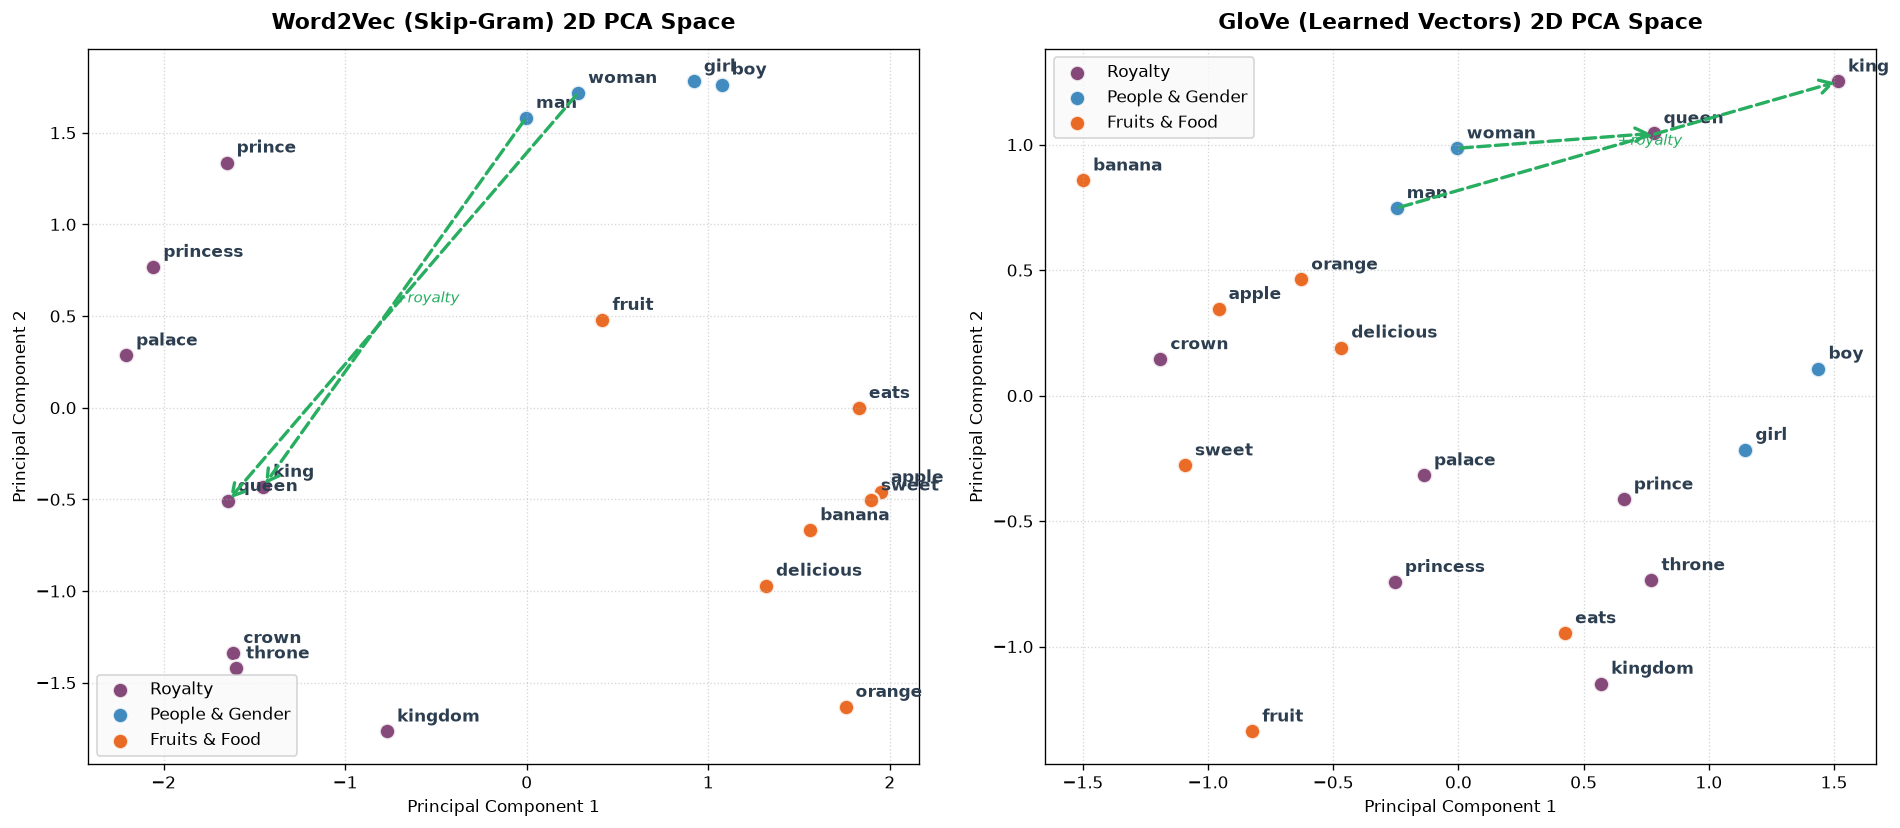

In [9]:
# Define words to plot and category assignments
categories = {
    "Royalty": ["king", "queen", "prince", "princess", "kingdom", "palace", "crown", "throne"],
    "People & Gender": ["man", "woman", "boy", "girl"],
    "Fruits & Food": ["apple", "banana", "orange", "fruit", "delicious", "sweet", "eats"]
}

category_colors = {
    "Royalty": "#702963",          # Royal Purple
    "People & Gender": "#1F77B4",  # Steel Blue
    "Fruits & Food": "#E65100"     # Deep Orange
}

plot_words = [w for group in categories.values() for w in group]
word_to_cat = {w: cat for cat, group in categories.items() for w in group}

# Extract vectors
w2v_mat = np.array([w2v_skipgram.wv[w] for w in plot_words])
glove_mat = np.array([glove_vectors[w2i[w]] for w in plot_words])

# Apply PCA to project to 2D
pca_w2v = PCA(n_components=2, random_state=42).fit_transform(w2v_mat)
pca_glove = PCA(n_components=2, random_state=42).fit_transform(glove_mat)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=120)

def render_embedding_plot(ax, coords_2d, words, title):
    coords_dict = {w: coords_2d[idx] for idx, w in enumerate(words)}
    
    for cat_name, color in category_colors.items():
        cat_words = [w for w in words if word_to_cat[w] == cat_name]
        xs = [coords_dict[w][0] for w in cat_words]
        ys = [coords_dict[w][1] for w in cat_words]
        ax.scatter(xs, ys, c=color, label=cat_name, s=90, alpha=0.85, edgecolors="white", linewidth=1.5)
        
        for w in cat_words:
            ax.annotate(
                w,
                (coords_dict[w][0], coords_dict[w][1]),
                textcoords="offset points",
                xytext=(6, 6),
                fontsize=10,
                fontweight="semibold",
                color="#2C3E50"
            )
            
    # Draw analogy arrows: man -> king and woman -> queen
    if all(w in coords_dict for w in ["man", "king", "woman", "queen"]):
        ax.annotate(
            "", xy=coords_dict["king"], xytext=coords_dict["man"],
            arrowprops=dict(arrowstyle="->, head_width=0.4, head_length=0.7", color="#27AE60", lw=2, ls="--")
        )
        ax.annotate(
            "", xy=coords_dict["queen"], xytext=coords_dict["woman"],
            arrowprops=dict(arrowstyle="->, head_width=0.4, head_length=0.7", color="#27AE60", lw=2, ls="--")
        )
        # Midpoint labels for analogy vector
        mid_m_k = (coords_dict["man"] + coords_dict["king"]) / 2.0
        ax.text(mid_m_k[0], mid_m_k[1], "+royalty", color="#27AE60", fontsize=9, fontstyle="italic")
        
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Principal Component 1", fontsize=10)
    ax.set_ylabel("Principal Component 2", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(frameon=True, facecolor="#F9F9F9", loc="best")

render_embedding_plot(axes[0], pca_w2v, plot_words, "Word2Vec (Skip-Gram) 2D PCA Space")
render_embedding_plot(axes[1], pca_glove, plot_words, "GloVe (Learned Vectors) 2D PCA Space")

plt.tight_layout()
plt.show()

---
## 7. Laboratory Summary & Key Insights

| Mechanism / Concept | Word2Vec (Skip-Gram / CBOW) | GloVe | PPMI + TruncatedSVD |
| :--- | :--- | :--- | :--- |
| **Core Philosophy** | Predictive local window model | Global matrix factorization + Least squares | Global matrix factorization (LSA) |
| **Objective Function** | Cross-entropy with negative sampling | Weighted squared log-loss ($J = \sum f(X)(w^\top \tilde{w} - \log X)^2$) | Frobenius reconstruction loss on PPMI |
| **Frequent Word Handling** | Probabilistic subsampling $P(\text{drop}) = 1 - \sqrt{t / f(w)}$ | Soft capping weight $f(x) = (x / x_{\max})^\alpha$ | Normalization by marginal probabilities |
| **Linear Analogies** | Preserved ($A - B + C \approx D$) | Preserved ($w_i^\top \tilde{w}_k = \log P_{ik} - \dots$) | Partially preserved |
| **Computational Profile** | Scales linearly with corpus tokens | Scales with unique non-zero co-occurrences $|X|$ | $O(V^2)$ co-occurrence matrix sizing |

### Conclusion
Both Word2Vec and GloVe successfully map discrete textual tokens into continuous vector spaces where semantic
similarity aligns with cosine similarity, and categorical concepts cluster cleanly together.
GloVe achieves this by converting global co-occurrence statistics into a linear regression problem, while Word2Vec
learns through binary classification on positive context windows and negative noise samples.